In [9]:
# load relevvant libraries & dataset
from bovw_pipeline import *
import sys
import matplotlib.pyplot as plt

tr_paths, y_tr, class_names = load_dataset("MIT_split/train")
te_paths, y_te, te_class_names = load_dataset("MIT_split/test")

Matplotlib is building the font cache; this may take a moment.


In [10]:
# Check the number of classes in the training and test datasets
assert class_names == te_class_names, "Class names in training and test datasets do not match."
print(class_names)
print("train", len(tr_paths), "test", len(te_paths))
print("train counts", np.unique(y_tr, return_counts=True))
print("test counts", np.unique(y_te, return_counts=True))
print("kernel python", sys.executable)

img = cv2.imread(tr_paths[0])
print("first image shape", img.shape)

['coast', 'forest', 'highway', 'insidecity', 'mountain', 'opencountry', 'street', 'tallbuilding']
train 1882 test 806
train counts (array([0, 1, 2, 3, 4, 5, 6, 7]), array([252, 230, 182, 216, 262, 287, 204, 249]))
test counts (array([0, 1, 2, 3, 4, 5, 6, 7]), array([108,  98,  78,  92, 112, 123,  88, 107]))
kernel python /Users/chizobawisdom/Portfolio/Machine_Vision/bovw-project/.venv/bin/python
first image shape (256, 256, 3)


In [11]:
for i, name in enumerate(class_names):
    print(f"{name:12s} train={np.sum(y_tr == i):4d}  test={np.sum(y_te == i):4d}")

coast        train= 252  test= 108
forest       train= 230  test=  98
highway      train= 182  test=  78
insidecity   train= 216  test=  92
mountain     train= 262  test= 112
opencountry  train= 287  test= 123
street       train= 204  test=  88
tallbuilding train= 249  test= 107


In [12]:
# density of SIFT features
desc, ys = extract_dense_sift(tr_paths[0])
print("deiscriptor shape", desc.shape)
print("y-coordinates from", ys.min(), "to", ys.max())
print("first descriptor (first 10 values)", desc[0][:10])

deiscriptor shape (961, 128)
y-coordinates from 8.0 to 248.0
first descriptor (first 10 values) [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


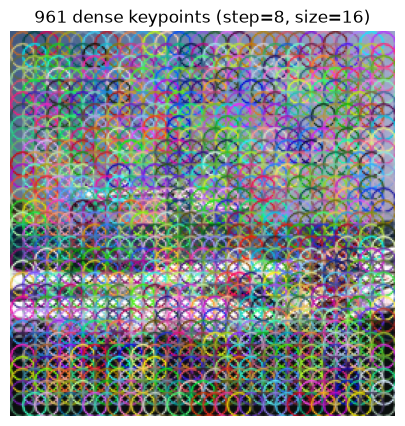

In [18]:
# to see the grid of SIFT features, we can plot the keypoints on the image
img = cv2.cvtColor(cv2.resize(cv2.imread(tr_paths[0]), (IMG_SIZE, IMG_SIZE)), cv2.COLOR_BGR2RGB)
kps = dense_keypoints()
vis = cv2.drawKeypoints(img, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(vis)
plt.title(f"{len(kps)} dense keypoints (step={STEP}, size={KP_SIZE})")
plt.axis("off")
plt.show()

In [19]:
import time
t0 = time.time()
tr_desc, tr_ys = extract_all(tr_paths)
print(f"done in {time.time() - t0:.0f}s")
print("images:", len(tr_desc))
print("total descriptors:", sum(len(d) for d in tr_desc))

done in 79s
images: 1882
total descriptors: 1808602


In [ ]:
t0 = time.time()
kmeans = build_codebook(tr_desc, k=512)
print(f"codebook built in {time.time() - t0:.0f}s")
print("cluster centres shape:", kmeans.cluster_centers_.shape)   

codebook built in 25s
cluster centres shape: (512, 128)


In [21]:
desc, ys = tr_desc[0], tr_ys[0]
words = kmeans.predict(desc)                     
hist = np.bincount(words, minlength=512)

print("first 10 word ids:", words[:10])
print("histogram sum:", hist.sum(), "| descriptors:", len(desc))   
print("most frequent word appears", hist.max(), "times")
print("distinct words used:", (hist > 0).sum(), "of 512")

first 10 word ids: [252 252 252 252 252 252 252 252 252 252]
histogram sum: 961 | descriptors: 961
most frequent word appears 199 times
distinct words used: 68 of 512


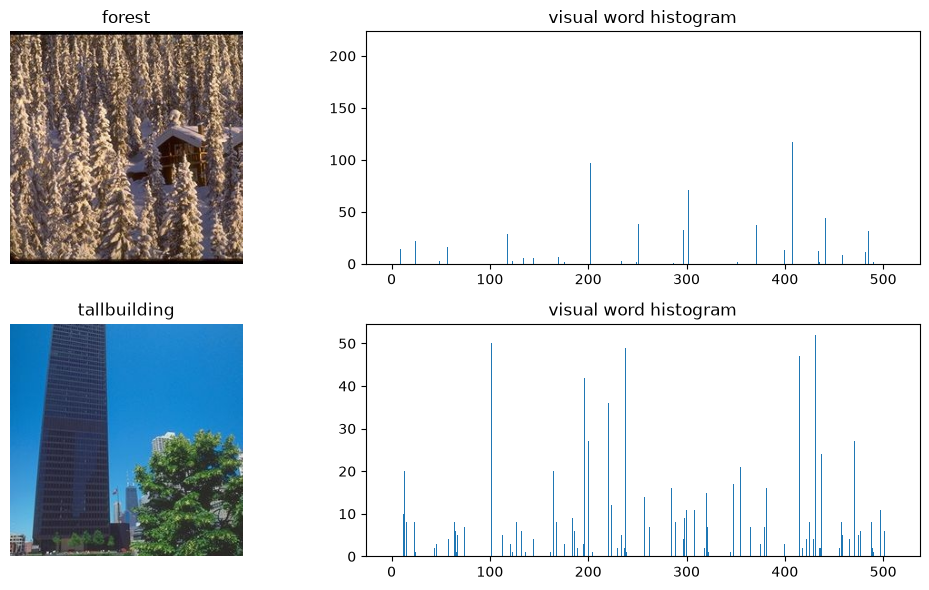

In [22]:
# Compare different classes
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, cls in enumerate(["forest", "tallbuilding"]):
    idx = np.where(y_tr == class_names.index(cls))[0][0]
    d, y = tr_desc[idx], tr_ys[idx]
    h = np.bincount(kmeans.predict(d), minlength=512)
    img = cv2.cvtColor(cv2.imread(tr_paths[idx]), cv2.COLOR_BGR2RGB)
    axes[row, 0].imshow(img); axes[row, 0].set_title(cls); axes[row, 0].axis("off")
    axes[row, 1].bar(range(512), h); axes[row, 1].set_title("visual word histogram")
plt.tight_layout(); plt.show()

In [ ]:
feat0 = encode_image(desc, ys, kmeans, level=0)
feat1 = encode_image(desc, ys, kmeans, level=1)
print("level 0:", feat0.shape)     
print("level 1:", feat1.shape)     
print("norm of each block:", np.linalg.norm(feat1.reshape(4, 512), axis=1))

level 0: (512,)
level 1: (2048,)
norm of each block: [1.         0.99999994 1.         1.        ]


In [24]:
t0 = time.time()
X_tr = encode_all(tr_desc, tr_ys, kmeans)
print(f"train encoded in {time.time() - t0:.0f}s, shape: {X_tr.shape}")  

te_desc, te_ys = extract_all(te_paths)
X_te = encode_all(te_desc, te_ys, kmeans)
print("test shape:", X_te.shape)                                          

train encoded in 6s, shape: (1882, 2048)
test shape: (806, 2048)


In [25]:
clf = make_pipeline(StandardScaler(),
                    PCA(n_components=64, random_state=42),
                    SVC(kernel="rbf"))

skf = StratifiedKFold(n_splits=8, shuffle=True, random_state=42)
scores = cross_val_score(clf, X_tr, y_tr, cv=skf, n_jobs=-1)
print("fold scores:", scores.round(3))
print(f"CV accuracy: {scores.mean():.3f} +/- {scores.std():.3f}")

fold scores: [0.788 0.881 0.872 0.838 0.826 0.885 0.834 0.821]
CV accuracy: 0.843 +/- 0.032


In [26]:
# Experiment 1: Impact of spatial pyramid level on classification accuracy
X_tr0 = encode_all(tr_desc, tr_ys, kmeans, level=0)
scores0 = cross_val_score(clf, X_tr0, y_tr, cv=skf, n_jobs=-1)
print("level 0 folds:", scores0.round(3))
print(f"level 0 (no pyramid): {scores0.mean():.3f} +/- {scores0.std():.3f}")
print(f"level 1 (pyramid):    {scores.mean():.3f} +/- {scores.std():.3f}")

level 0 folds: [0.809 0.869 0.885 0.813 0.817 0.868 0.847 0.838]
level 0 (no pyramid): 0.843 +/- 0.027
level 1 (pyramid):    0.843 +/- 0.032


In [27]:
# Papers figure 8 test
def cv_acc(X, n_pca):
    steps = [StandardScaler()]
    if n_pca:
        steps.append(PCA(n_components=n_pca, random_state=42))
    steps.append(SVC(kernel="rbf"))
    s = cross_val_score(make_pipeline(*steps), X, y_tr, cv=skf, n_jobs=-1)
    return s.mean(), s.std()

print("PCA comps | level 0        | level 1")
for n in [32, 64, 128, 256, None]:
    m0, s0 = cv_acc(X_tr0, n)
    m1, s1 = cv_acc(X_tr, n)
    print(f"{str(n):9s} | {m0:.3f} +/- {s0:.3f} | {m1:.3f} +/- {s1:.3f}")

PCA comps | level 0        | level 1
32        | 0.834 +/- 0.029 | 0.839 +/- 0.032
64        | 0.843 +/- 0.027 | 0.843 +/- 0.032
128       | 0.844 +/- 0.027 | 0.844 +/- 0.030
256       | 0.846 +/- 0.029 | 0.849 +/- 0.029
None      | 0.849 +/- 0.028 | 0.823 +/- 0.030


Test accuracy: 0.842
              precision    recall  f1-score   support

       coast       0.77      0.80      0.78       108
      forest       0.92      0.97      0.95        98
     highway       0.92      0.86      0.89        78
  insidecity       0.91      0.79      0.85        92
    mountain       0.80      0.88      0.84       112
 opencountry       0.73      0.67      0.70       123
      street       0.90      0.89      0.89        88
tallbuilding       0.85      0.93      0.89       107

    accuracy                           0.84       806
   macro avg       0.85      0.85      0.85       806
weighted avg       0.84      0.84      0.84       806



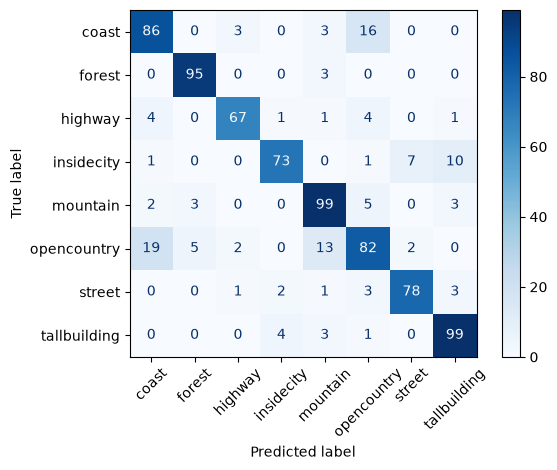

In [28]:
clf.fit(X_tr, y_tr)
y_pred = clf.predict(X_te)
print(f"Test accuracy: {accuracy_score(y_te, y_pred):.3f}")
print(classification_report(y_te, y_pred, target_names=class_names))

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_te, y_pred, display_labels=class_names, xticks_rotation=45, cmap="Blues")
plt.tight_layout(); plt.show()

In [29]:
# Experiment 2: Impact of codebook size on classification accuracy
for k in [32, 128, 512, 1024, 2048]:
    t0 = time.time()
    km = build_codebook(tr_desc, k=k)
    Xk = encode_all(tr_desc, tr_ys, km, level=1)
    m, s = cv_acc(Xk, 64)
    print(f"k={k:5d} | {m:.3f} +/- {s:.3f} | {time.time() - t0:.0f}s")

k=   32 | 0.786 +/- 0.031 | 11s
k=  128 | 0.828 +/- 0.031 | 11s
k=  512 | 0.843 +/- 0.032 | 25s
k= 1024 | 0.851 +/- 0.027 | 54s
k= 2048 | 0.857 +/- 0.025 | 83s


19 opencountry images predicted as coast


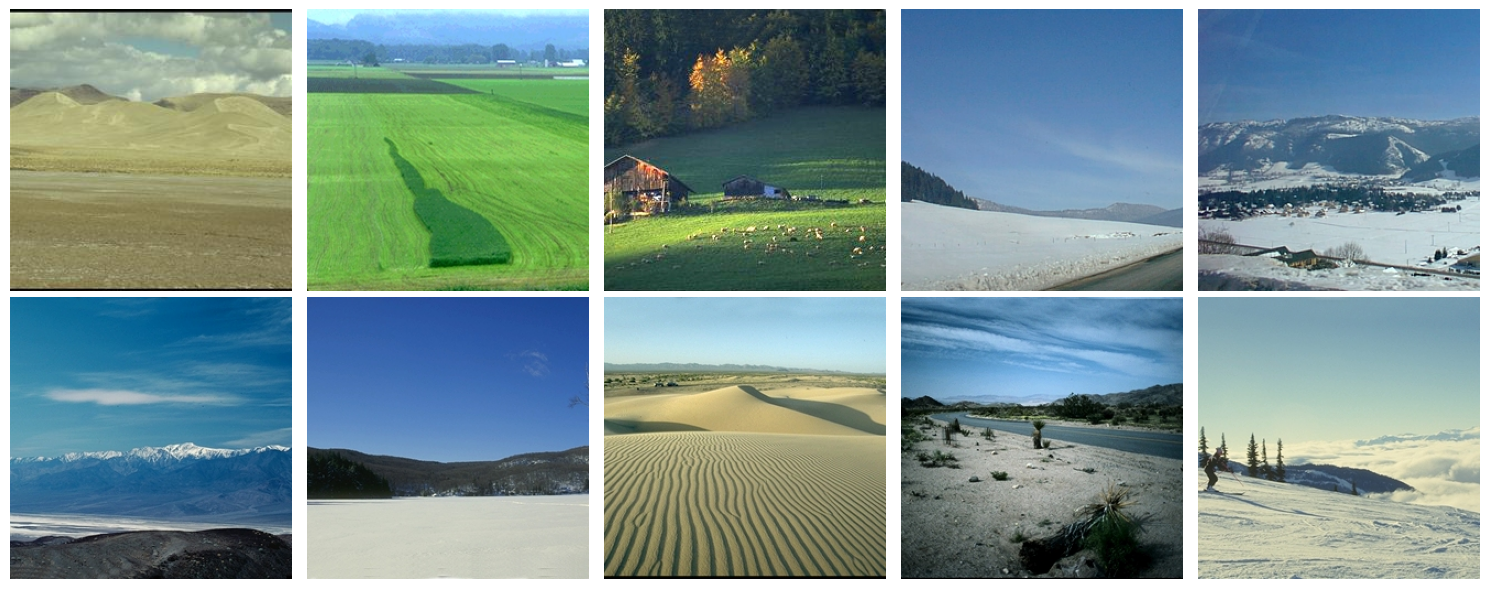

In [ ]:
# Possible confusion between opencountry and coast
cls_a, cls_b = class_names.index("opencountry"), class_names.index("coast")
errs = np.where((y_te == cls_a) & (y_pred == cls_b))[0]
print(len(errs), "opencountry images predicted as coast")

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, i in zip(axes.ravel(), errs[:10]):
    ax.imshow(cv2.cvtColor(cv2.imread(te_paths[i]), cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout(); plt.show()

16 coast images predicted as opencountry


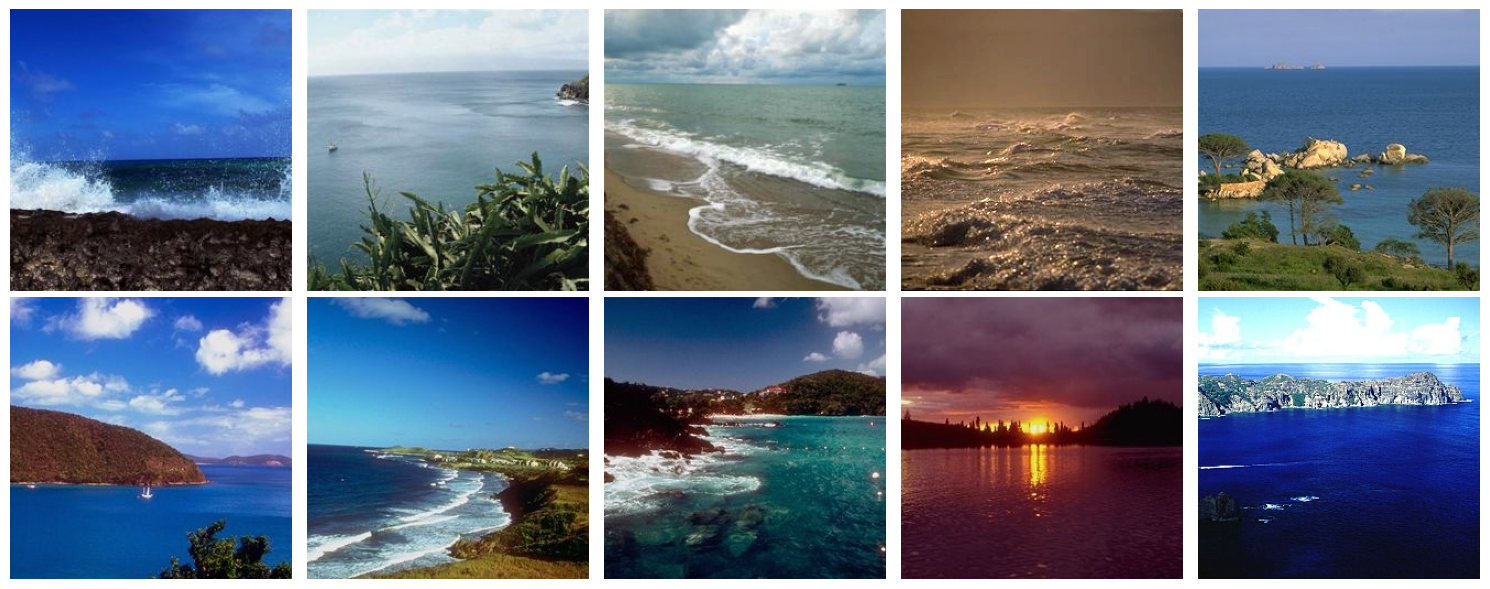

In [31]:
# Possible confusion between opencountry and coast
cls_a, cls_b = class_names.index("coast"), class_names.index("opencountry")
errs = np.where((y_te == cls_a) & (y_pred == cls_b))[0]
print(len(errs), "coast images predicted as opencountry")

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, i in zip(axes.ravel(), errs[:10]):
    ax.imshow(cv2.cvtColor(cv2.imread(te_paths[i]), cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout(); plt.show()